In [14]:
import pandas as pd
import numpy as np

csv_path = "../results/mcts_pi_svgp_cs_extract_YasMarina_10/traj_config_mcts_dpw_pi_svgp_cpp_cs_extract_s42_YasMarina_10_20260219_110439.csv"

df = pd.read_csv(csv_path, comment="#")
print(f"Shape: {df.shape}")
df = df.dropna(subset=['Aa_action_list'])
df = df.drop(['pred_vx', 'pred_vy', 'pred_omega'], axis=1)

# Convert semicolon-separated action list strings to numpy arrays
df['Aa_action_list'] = df['Aa_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))
df['Asv_action_list'] = df['Asv_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))

print(f"Example Aa_action_list (step 0): {df['Aa_action_list'].iloc[0]}")
print(f"Type: {type(df['Aa_action_list'].iloc[0])}, Length: {len(df['Aa_action_list'].iloc[0])}")

Shape: (3048, 16)
Example Aa_action_list (step 0): [ 9.449311  8.345898  7.453466  9.252404  5.442439 -1.647828  7.205273
  8.775101]
Type: <class 'numpy.ndarray'>, Length: 8


In [15]:
df.columns

Index(['S_x', 'S_y', 'S_delta', 'S_vel', 'S_psi', 'S_omega', 'S_beta', 'A_a',
       'A_sv', 'Aa_action_list', 'Asv_action_list', 'C_alpha',
       'C_alpha_smooth'],
      dtype='object')

In [16]:
# required row

row = df.iloc[20]

In [17]:
row

S_x                                                         4.246556
S_y                                                         0.706554
S_delta                                                    -0.008689
S_vel                                                       7.093549
S_psi                                                       0.115299
S_omega                                                    -0.513699
S_beta                                                      0.010515
A_a                                                         5.152157
A_sv                                                       -1.436311
Aa_action_list     [5.152157, 9.204883, 2.158556, 7.289248, 1.298...
Asv_action_list    [-1.436311, 1.461619, 1.981736, -0.681387, -1....
C_alpha                                                    97.630125
C_alpha_smooth                                             99.457205
Name: 26, dtype: object

In [18]:
import torch
import json
from sklearn.preprocessing import StandardScaler

# ── Load PI-SVGP model ──────────────────────────────────────────────────────
model_path = "../models/pi_svgp_mcts_data/mcts_svgp_best_params.npz"
data = np.load(model_path, allow_pickle=False)

# Kernel hyperparams
theta = torch.tensor(data['model__theta_opt'], dtype=torch.float64)

# Inducing points (augmented: input + latent)
Zx = torch.tensor(data['model__Zx_opt'], dtype=torch.float64)   # (M, 6)
Zh = torch.tensor(data['model__Zh_opt'], dtype=torch.float64)   # (M, 2)
Z_aug = torch.cat([Zx, Zh], dim=1)                              # (M, 8)
M = Z_aug.shape[0]

# Variational inducing means and log-stds
m_opt = torch.tensor(data['model__m_opt'], dtype=torch.float64)            # (M, 9)
m_logstd = torch.tensor(data['model__m_logstd_opt'], dtype=torch.float64)  # (M, 9)

# Output bias
output_bias = torch.tensor(data['model__output_bias_opt'], dtype=torch.float64)  # (9,)

# Task latent means (for C_alpha interpolation)
h_mu_all = data['model__h_mu_opt']  # (3, 2)

# Input scaler
xmean = torch.tensor(data['xscaler__mean'], dtype=torch.float64)
xscale = torch.tensor(data['xscaler__scale'], dtype=torch.float64)

# ── Precompute kernel matrices ───────────────────────────────────────────────
def rbf_ard_kernel(X, Z, th):
    ls, sigma = th[:-1], th[-1]
    Xs, Zs = X / ls, Z / ls
    dist = (Xs**2).sum(1, keepdim=True) + (Zs**2).sum(1, keepdim=True).T - 2*Xs@Zs.T
    return (sigma**2) * torch.exp(-0.5 * dist)

K_mm = rbf_ard_kernel(Z_aug, Z_aug, theta) + torch.eye(M, dtype=torch.float64) * 1e-6
K_mm_inv = torch.linalg.inv(K_mm)
alpha_gp = K_mm_inv @ m_opt  # (M, 9) for fast mean

# ── C_alpha → latent interpolation ───────────────────────────────────────────
c_alpha_anchors = np.array([104.89, 86.42, 49.47])
h_anchors = h_mu_all[:3]
calpha_slopes = np.zeros(h_anchors.shape[1])
calpha_intercepts = np.zeros(h_anchors.shape[1])
for d in range(h_anchors.shape[1]):
    calpha_slopes[d], calpha_intercepts[d] = np.polyfit(c_alpha_anchors, h_anchors[:, d], 1)

def interpolate_hp_mu(c_alpha):
    c = np.clip(c_alpha, c_alpha_anchors.min(), c_alpha_anchors.max())
    return torch.tensor(calpha_slopes * c + calpha_intercepts, dtype=torch.float64)

# ── Constants ────────────────────────────────────────────────────────────────
POSITIVE_IDX = [0, 1, 2, 4, 5, 6]
PACEJKA_NAMES = ["Bf", "Cf", "Df", "Ef", "Br", "Cr", "Dr", "Er", "Frx"]
VP = dict(lf=0.15875, lr=0.17145, mass=3.74, Iz=0.04712,
          s_min=-0.4189, s_max=0.4189, sv_min=-3.2, sv_max=3.2,
          v_switch=7.319, a_max=9.51, v_min=-5.0, v_max=20.0)
BASE_DT = 0.02
DT = 0.04

print(f"Model loaded: M={M}, Z_aug={Z_aug.shape}, m_logstd={m_logstd.shape}")

Model loaded: M=50, Z_aug=torch.Size([50, 8]), m_logstd=torch.Size([50, 9])


In [19]:
N_SAMPLES = 500  # MC samples for variance propagation through Pacejka


def extract_features(state_7, action_2, dt=BASE_DT):
    """state_7: [x,y,delta,v,psi,omega,beta], action_2: [accel, steer_vel]
    -> features: (6,) [VX, VY, YAW_RATE, STEERING_FB, THROTTLE_CMD, STEERING_CMD]"""
    v, delta, omega, beta = state_7[3], state_7[2], state_7[5], state_7[6]
    accel, sv = action_2[0], action_2[1]
    return torch.tensor([
        v * torch.cos(beta), v * torch.sin(beta), omega,
        delta, accel * dt, sv * dt,
    ], dtype=torch.float64)


def gp_predict_mean_and_var(features_1d, hp_mu):
    """GP posterior mean (9,) and variance (9,) in raw (pre-constraint) space."""
    feat_norm = (features_1d.unsqueeze(0) - xmean) / xscale
    X_aug = torch.cat([feat_norm, hp_mu.unsqueeze(0)], dim=1)  # (1, 8)

    K_nm = rbf_ard_kernel(X_aug, Z_aug, theta)  # (1, M)
    al = K_nm @ K_mm_inv                         # (1, M)

    raw_mean = (al @ m_opt).squeeze(0) + output_bias  # (9,)

    sigma2 = theta[-1] ** 2
    reduction = (al * K_nm).sum()
    var = torch.zeros(9, dtype=torch.float64)
    for p in range(9):
        S_p = torch.exp(2.0 * m_logstd[:, p])
        var[p] = sigma2 - reduction + (al.squeeze(0)**2 * S_p).sum()

    return raw_mean, var


def constrain_pacejka(raw):
    """Softplus on Bf,Cf,Df,Br,Cr,Dr. Works on (9,) or (N,9)."""
    out = raw.clone()
    if raw.dim() == 1:
        for i in POSITIVE_IDX:
            out[i] = torch.nn.functional.softplus(raw[i])
    else:
        out[:, POSITIVE_IDX] = torch.nn.functional.softplus(raw[:, POSITIVE_IDX])
    return out


def pacejka_physics_batch(features_6, params_N9, dt=BASE_DT):
    """Pacejka physics for N sampled param sets. features_6: (6,), params_N9: (N,9).
    Returns (N, 3) next [VX, VY, YAW_RATE]."""
    VX, VY, YR = features_6[0], features_6[1], features_6[2]
    steer = features_6[3] + features_6[5]
    Bf,Cf,Df,Ef = params_N9[:,0], params_N9[:,1], params_N9[:,2], params_N9[:,3]
    Br,Cr,Dr,Er,Frx = params_N9[:,4], params_N9[:,5], params_N9[:,6], params_N9[:,7], params_N9[:,8]

    alphaf = steer - torch.atan2(VP['lf']*YR + VY, torch.abs(VX))
    alphar = torch.atan2(VP['lr']*YR - VY, torch.abs(VX))

    Ffy = Df*torch.sin(Cf*torch.atan(Bf*alphaf - Ef*(Bf*alphaf - torch.atan(Bf*alphaf))))
    Fry = Dr*torch.sin(Cr*torch.atan(Br*alphar - Er*(Br*alphar - torch.atan(Br*alphar))))

    dVX = (1/VP['mass'])*(Frx - Ffy*torch.sin(steer)) + VY*YR
    dVY = (1/VP['mass'])*(Fry + Ffy*torch.cos(steer)) - VX*YR
    dYR = (1/VP['Iz'])*(Ffy*VP['lf']*torch.cos(steer) - Fry*VP['lr'])

    return torch.stack([VX + dVX*dt, VY + dVY*dt, YR + dYR*dt], dim=1)  # (N, 3)


def step_with_uncertainty(state_7, action_2, hp_mu, dt=BASE_DT):
    """One substep -> mean [VX,VY,omega], var [VX,VY,omega] via MC, plus next_state.
    Returns: next_state_7, body_mean(3,), body_var(3,)"""
    features = extract_features(state_7, action_2, dt)
    raw_mean, raw_var = gp_predict_mean_and_var(features, hp_mu)

    # Sample Pacejka params from GP posterior: N(raw_mean, diag(raw_var))
    raw_std = torch.sqrt(torch.clamp(raw_var, min=1e-12))
    eps = torch.randn(N_SAMPLES, 9, dtype=torch.float64)
    raw_samples = raw_mean.unsqueeze(0) + eps * raw_std.unsqueeze(0)  # (N, 9)
    constrained_samples = constrain_pacejka(raw_samples)              # (N, 9)

    # Run physics for all samples
    body_samples = pacejka_physics_batch(features, constrained_samples, dt)  # (N, 3)
    body_mean = body_samples.mean(dim=0)  # (3,) [VX, VY, omega]
    body_var  = body_samples.var(dim=0)   # (3,)

    # Propagate state using the mean prediction (deterministic path)
    constrained_mean = constrain_pacejka(raw_mean)
    VX, VY, YR = features[0], features[1], features[2]
    steer = features[3] + features[5]
    Bf,Cf,Df,Ef,Br,Cr,Dr,Er,Frx = constrained_mean
    alphaf = steer - torch.atan2(VP['lf']*YR + VY, torch.abs(VX))
    alphar = torch.atan2(VP['lr']*YR - VY, torch.abs(VX))
    Ffy = Df*torch.sin(Cf*torch.atan(Bf*alphaf - Ef*(Bf*alphaf - torch.atan(Bf*alphaf))))
    Fry = Dr*torch.sin(Cr*torch.atan(Br*alphar - Er*(Br*alphar - torch.atan(Br*alphar))))
    next_VX = VX + dt*(1/VP['mass'])*(Frx - Ffy*torch.sin(steer)) + dt*VY*YR
    next_VY = VY + dt*(1/VP['mass'])*(Fry + Ffy*torch.cos(steer)) - dt*VX*YR
    next_YR = YR + dt*(1/VP['Iz'])*(Ffy*VP['lf']*torch.cos(steer) - Fry*VP['lr'])

    x,y,delta,v,psi = state_7[0],state_7[1],state_7[2],state_7[3],state_7[4]
    accel, sv = action_2[0], action_2[1]
    omega_pred = next_YR
    beta_pred = torch.atan2(next_VY, next_VX + 1e-8)
    next_state = torch.stack([
        x + dt*v*torch.cos(beta_pred + psi), y + dt*v*torch.sin(beta_pred + psi),
        delta + dt*sv, v + dt*accel, psi + dt*omega_pred, omega_pred, beta_pred,
    ])
    return next_state, body_mean, body_var


def rollout_row(row, n_samples=N_SAMPLES):
    """Roll out best-path actions. Returns per-action mean/var of [VX, VY, omega]."""
    state = torch.tensor([row.S_x, row.S_y, row.S_delta, row.S_vel,
                          row.S_psi, row.S_omega, row.S_beta], dtype=torch.float64)
    hp_mu = interpolate_hp_mu(row.C_alpha_smooth)
    accels, steers = row.Aa_action_list, row.Asv_action_list
    n_actions = min(len(accels), len(steers))

    vx_mean, vy_mean, omega_mean = [], [], []
    vx_var, vy_var, omega_var = [], [], []
    states = [state.numpy().copy()]
    cur = state.clone()

    for i in range(n_actions):
        action = torch.tensor([accels[i], steers[i]], dtype=torch.float64)
        # 2 substeps of BASE_DT
        s1, bm1, bv1 = step_with_uncertainty(cur, action, hp_mu, BASE_DT)
        s2, bm2, bv2 = step_with_uncertainty(s1, action, hp_mu, BASE_DT)
        # Store first-substep prediction (from the real state at this action)
        vx_mean.append(bm1[0].item()); vy_mean.append(bm1[1].item()); omega_mean.append(bm1[2].item())
        vx_var.append(bv1[0].item());  vy_var.append(bv1[1].item());  omega_var.append(bv1[2].item())
        states.append(s2.detach().numpy().copy())
        cur = s2.detach()

    return {
        "vx_mean": np.array(vx_mean), "vy_mean": np.array(vy_mean), "omega_mean": np.array(omega_mean),
        "vx_var": np.array(vx_var),   "vy_var": np.array(vy_var),   "omega_var": np.array(omega_var),
        "states": np.array(states),
    }

print("Helper functions defined (MC variance propagation through Pacejka).")

Helper functions defined (MC variance propagation through Pacejka).


In [20]:
import time

t0 = time.perf_counter()
res_mc = rollout_row(row)
t_mc = time.perf_counter() - t0
n_act = len(res_mc["vx_mean"])

print(f"=== Monte Carlo ({N_SAMPLES} samples) — {t_mc*1000:.1f} ms ===\n")
print(f"Actions in best path: {n_act}")
print(f"C_alpha_smooth: {row.C_alpha_smooth:.2f}")
print(f"Latent hp_mu:   {interpolate_hp_mu(row.C_alpha_smooth).numpy()}\n")

print(f"{'Step':>4}  {'VX_mean':>10} {'VX_std':>10}  {'VY_mean':>10} {'VY_std':>10}  {'omega_mean':>10} {'omega_std':>10}")
print("-" * 78)
for i in range(n_act):
    print(f"{i:4d}  {res_mc['vx_mean'][i]:10.4f} {np.sqrt(res_mc['vx_var'][i]):10.4f}"
          f"  {res_mc['vy_mean'][i]:10.4f} {np.sqrt(res_mc['vy_var'][i]):10.4f}"
          f"  {res_mc['omega_mean'][i]:10.4f} {np.sqrt(res_mc['omega_var'][i]):10.4f}")

=== Monte Carlo (500 samples) — 12.4 ms ===

Actions in best path: 11
C_alpha_smooth: 99.46
Latent hp_mu:   [0.15133551 2.15064001]

Step     VX_mean     VX_std     VY_mean     VY_std  omega_mean  omega_std
------------------------------------------------------------------------------
   0      7.1965     0.0222      0.1237     0.0308     -0.2664     0.4306
   1      7.4671     0.0286      0.1869     0.0574      0.0149     0.7654
   2      7.7136     0.0231      0.2283     0.0247      0.1042     0.3348
   3      7.8924     0.0276      0.1819     0.0482      0.5871     0.6507
   4      8.0732     0.0251      0.0085     0.0119      0.6121     0.1516
   5      8.0244     0.0231     -0.1624     0.0246      0.2211     0.3203
   6      7.9841     0.0210     -0.2203     0.0308      0.0218     0.4120
   7      8.1447     0.0242     -0.2031     0.0352     -0.3848     0.4856
   8      8.4237     0.0267     -0.0932     0.0405     -0.5715     0.5352
   9      8.4442     0.0298     -0.0170     0.01

In [21]:
def pacejka_from_raw(raw_params_9, features_6, dt=BASE_DT):
    """Differentiable: raw GP output (9,) -> constrained Pacejka -> physics -> [VX,VY,omega] (3,)."""
    constrained = raw_params_9.clone()
    for i in POSITIVE_IDX:
        constrained[i] = torch.nn.functional.softplus(raw_params_9[i])
    VX, VY, YR = features_6[0], features_6[1], features_6[2]
    steer = features_6[3] + features_6[5]
    Bf,Cf,Df,Ef,Br,Cr,Dr,Er,Frx = constrained

    alphaf = steer - torch.atan2(VP['lf']*YR + VY, torch.abs(VX))
    alphar = torch.atan2(VP['lr']*YR - VY, torch.abs(VX))
    Ffy = Df*torch.sin(Cf*torch.atan(Bf*alphaf - Ef*(Bf*alphaf - torch.atan(Bf*alphaf))))
    Fry = Dr*torch.sin(Cr*torch.atan(Br*alphar - Er*(Br*alphar - torch.atan(Br*alphar))))

    next_VX = VX + dt*((1/VP['mass'])*(Frx - Ffy*torch.sin(steer)) + VY*YR)
    next_VY = VY + dt*((1/VP['mass'])*(Fry + Ffy*torch.cos(steer)) - VX*YR)
    next_YR = YR + dt*(1/VP['Iz'])*(Ffy*VP['lf']*torch.cos(steer) - Fry*VP['lr'])
    return torch.stack([next_VX, next_VY, next_YR])


def step_delta_method(state_7, action_2, hp_mu, dt=BASE_DT):
    """One substep using delta method: Var[output] = J @ diag(var) @ J^T.
    Returns: next_state_7, body_mean(3,), body_var(3,)"""
    features = extract_features(state_7, action_2, dt)
    raw_mean, raw_var = gp_predict_mean_and_var(features, hp_mu)

    # Jacobian of (constrain + physics) w.r.t. raw Pacejka params
    raw_input = raw_mean.detach().requires_grad_(True)
    J = torch.autograd.functional.jacobian(
        lambda r: pacejka_from_raw(r, features.detach(), dt), raw_input
    )  # (3, 9)

    # Delta method: Var[f(x)] ≈ J @ diag(var_x) @ J^T  ->  diag = sum(J^2 * var, dim=1)
    body_var = (J ** 2 * raw_var.unsqueeze(0)).sum(dim=1)  # (3,)

    # Mean: just run forward with the GP mean
    body_mean = pacejka_from_raw(raw_mean.detach(), features.detach(), dt)

    # Propagate state deterministically (same as MC version)
    x,y,delta,v,psi = state_7[0],state_7[1],state_7[2],state_7[3],state_7[4]
    accel, sv = action_2[0], action_2[1]
    omega_pred = body_mean[2]
    beta_pred = torch.atan2(body_mean[1], body_mean[0] + 1e-8)
    next_state = torch.stack([
        x + dt*v*torch.cos(beta_pred + psi), y + dt*v*torch.sin(beta_pred + psi),
        delta + dt*sv, v + dt*accel, psi + dt*omega_pred, omega_pred, beta_pred,
    ])
    return next_state, body_mean.detach(), body_var.detach()


def rollout_row_delta(row):
    """Roll out best-path actions using delta method for variance."""
    state = torch.tensor([row.S_x, row.S_y, row.S_delta, row.S_vel,
                          row.S_psi, row.S_omega, row.S_beta], dtype=torch.float64)
    hp_mu = interpolate_hp_mu(row.C_alpha_smooth)
    accels, steers = row.Aa_action_list, row.Asv_action_list
    n_actions = min(len(accels), len(steers))

    vx_mean, vy_mean, omega_mean = [], [], []
    vx_var, vy_var, omega_var = [], [], []
    cur = state.clone()

    for i in range(n_actions):
        action = torch.tensor([accels[i], steers[i]], dtype=torch.float64)
        s1, bm1, bv1 = step_delta_method(cur, action, hp_mu, BASE_DT)
        s2, bm2, bv2 = step_delta_method(s1.detach(), action, hp_mu, BASE_DT)
        vx_mean.append(bm1[0].item()); vy_mean.append(bm1[1].item()); omega_mean.append(bm1[2].item())
        vx_var.append(bv1[0].item());  vy_var.append(bv1[1].item());  omega_var.append(bv1[2].item())
        cur = s2.detach()

    return {
        "vx_mean": np.array(vx_mean), "vy_mean": np.array(vy_mean), "omega_mean": np.array(omega_mean),
        "vx_var": np.array(vx_var),   "vy_var": np.array(vy_var),   "omega_var": np.array(omega_var),
    }

# Run delta method
t0 = time.perf_counter()
res_delta = rollout_row_delta(row)
t_delta = time.perf_counter() - t0

print(f"=== Delta Method (Jacobian) — {t_delta*1000:.1f} ms ===\n")
print(f"{'Step':>4}  {'VX_mean':>10} {'VX_std':>10}  {'VY_mean':>10} {'VY_std':>10}  {'omega_mean':>10} {'omega_std':>10}")
print("-" * 78)
for i in range(n_act):
    print(f"{i:4d}  {res_delta['vx_mean'][i]:10.4f} {np.sqrt(res_delta['vx_var'][i]):10.4f}"
          f"  {res_delta['vy_mean'][i]:10.4f} {np.sqrt(res_delta['vy_var'][i]):10.4f}"
          f"  {res_delta['omega_mean'][i]:10.4f} {np.sqrt(res_delta['omega_var'][i]):10.4f}")

# Comparison summary
print(f"\n=== Timing ===")
print(f"Monte Carlo ({N_SAMPLES} samples): {t_mc*1000:.1f} ms")
print(f"Delta method (Jacobian):    {t_delta*1000:.1f} ms")
print(f"Speedup:                    {t_mc/t_delta:.1f}x")

print(f"\n=== Max absolute difference (std) ===")
print(f"VX_std:    {np.max(np.abs(np.sqrt(res_mc['vx_var']) - np.sqrt(res_delta['vx_var']))):.6f}")
print(f"VY_std:    {np.max(np.abs(np.sqrt(res_mc['vy_var']) - np.sqrt(res_delta['vy_var']))):.6f}")
print(f"omega_std: {np.max(np.abs(np.sqrt(res_mc['omega_var']) - np.sqrt(res_delta['omega_var']))):.6f}")

=== Delta Method (Jacobian) — 28.2 ms ===

Step     VX_mean     VX_std     VY_mean     VY_std  omega_mean  omega_std
------------------------------------------------------------------------------
   0      7.1971     0.0224      0.1321     0.0378     -0.4356     0.5062
   1      7.4665     0.0275      0.1895     0.1103     -0.3463     1.4471
   2      7.7131     0.0218      0.2337     0.0353     -0.0265     0.4795
   3      7.8925     0.0280      0.1999     0.0793      0.4927     1.0557
   4      8.0747     0.0245      0.0085     0.0169      0.5976     0.2124
   5      8.0233     0.0226     -0.1675     0.0299      0.3165     0.3907
   6      7.9840     0.0213     -0.2350     0.0404      0.1252     0.5493
   7      8.1462     0.0243     -0.2152     0.0516     -0.1946     0.6968
   8      8.4230     0.0272     -0.1041     0.0584     -0.2395     0.7546
   9      8.4422     0.0300     -0.0115     0.0372     -0.0589     0.4688
  10      8.3511     0.0366      0.0200     0.1659      0.7999  

In [22]:
# ── Batched helpers for particle-based state distribution ─────────────────────

def extract_features_batch(states_N7, action_2, dt=BASE_DT):
    """(N,7) states + (2,) action -> (N,6) features."""
    v, delta, omega, beta = states_N7[:,3], states_N7[:,2], states_N7[:,5], states_N7[:,6]
    N = states_N7.shape[0]
    return torch.stack([
        v * torch.cos(beta), v * torch.sin(beta), omega,
        delta, torch.full((N,), action_2[0].item()*dt, dtype=torch.float64),
        torch.full((N,), action_2[1].item()*dt, dtype=torch.float64),
    ], dim=1)  # (N, 6)


def gp_predict_mean_and_var_batch(features_N6, hp_mu):
    """(N,6) -> (N,9) mean, (N,9) var — batched GP prediction."""
    N = features_N6.shape[0]
    feat_norm = (features_N6 - xmean) / xscale                       # (N, 6)
    hp_tiled = hp_mu.unsqueeze(0).expand(N, -1)                      # (N, 2)
    X_aug = torch.cat([feat_norm, hp_tiled], dim=1)                   # (N, 8)

    K_nm = rbf_ard_kernel(X_aug, Z_aug, theta)                       # (N, M)
    al = K_nm @ K_mm_inv                                              # (N, M)

    raw_mean = al @ m_opt + output_bias                               # (N, 9)

    sigma2 = theta[-1] ** 2
    reduction = (al * K_nm).sum(dim=1)                                # (N,)
    var = torch.zeros(N, 9, dtype=torch.float64)
    for p in range(9):
        S_p = torch.exp(2.0 * m_logstd[:, p])                        # (M,)
        var[:, p] = sigma2 - reduction + (al**2 * S_p).sum(dim=1)

    return raw_mean, var


def pacejka_physics_full_batch(features_N6, params_N9, dt=BASE_DT):
    """(N,6) features, (N,9) params -> (N,3) next [VX,VY,YR]. Each row independent."""
    VX, VY, YR = features_N6[:,0], features_N6[:,1], features_N6[:,2]
    steer = features_N6[:,3] + features_N6[:,5]
    Bf,Cf,Df,Ef = params_N9[:,0], params_N9[:,1], params_N9[:,2], params_N9[:,3]
    Br,Cr,Dr,Er,Frx = params_N9[:,4], params_N9[:,5], params_N9[:,6], params_N9[:,7], params_N9[:,8]

    alphaf = steer - torch.atan2(VP['lf']*YR + VY, torch.abs(VX))
    alphar = torch.atan2(VP['lr']*YR - VY, torch.abs(VX))
    Ffy = Df*torch.sin(Cf*torch.atan(Bf*alphaf - Ef*(Bf*alphaf - torch.atan(Bf*alphaf))))
    Fry = Dr*torch.sin(Cr*torch.atan(Br*alphar - Er*(Br*alphar - torch.atan(Br*alphar))))

    dVX = (1/VP['mass'])*(Frx - Ffy*torch.sin(steer)) + VY*YR
    dVY = (1/VP['mass'])*(Fry + Ffy*torch.cos(steer)) - VX*YR
    dYR = (1/VP['Iz'])*(Ffy*VP['lf']*torch.cos(steer) - Fry*VP['lr'])
    return torch.stack([VX + dVX*dt, VY + dVY*dt, YR + dYR*dt], dim=1)


def kinematic_update_batch(states_N7, body_N3, action_2, dt=BASE_DT):
    """(N,7) states, (N,3) body [VX,VY,YR] -> (N,7) next states."""
    x,y,delta,v,psi = states_N7[:,0], states_N7[:,1], states_N7[:,2], states_N7[:,3], states_N7[:,4]
    accel, sv = action_2[0], action_2[1]
    omega_pred = body_N3[:, 2]
    beta_pred = torch.atan2(body_N3[:, 1], body_N3[:, 0] + 1e-8)
    return torch.stack([
        x + dt * v * torch.cos(beta_pred + psi),
        y + dt * v * torch.sin(beta_pred + psi),
        delta + dt * sv,
        v + dt * accel,
        psi + dt * omega_pred,
        omega_pred,
        beta_pred,
    ], dim=1)  # (N, 7)


def particle_substep(particles_N7, action_2, hp_mu, dt=BASE_DT):
    """One substep: each particle gets its own GP prediction + sampled Pacejka params.
    (N,7) -> (N,7) next particles."""
    features = extract_features_batch(particles_N7, action_2, dt)      # (N, 6)
    raw_mean, raw_var = gp_predict_mean_and_var_batch(features, hp_mu) # (N, 9) each
    raw_std = torch.sqrt(torch.clamp(raw_var, min=1e-12))
    # Sample one set of Pacejka params per particle
    raw_samples = raw_mean + torch.randn_like(raw_mean) * raw_std      # (N, 9)
    constrained = constrain_pacejka(raw_samples)                       # (N, 9)
    body = pacejka_physics_full_batch(features, constrained, dt)       # (N, 3)
    return kinematic_update_batch(particles_N7, body, action_2, dt)    # (N, 7)


def rollout_row_state_mc(row, n_samples=N_SAMPLES):
    """Particle-based rollout: propagate N particles through the full action sequence.
    Uncertainty compounds across steps. Returns per-action state mean (7,) and var (7,)."""
    state0 = torch.tensor([row.S_x, row.S_y, row.S_delta, row.S_vel,
                           row.S_psi, row.S_omega, row.S_beta], dtype=torch.float64)
    hp_mu = interpolate_hp_mu(row.C_alpha_smooth)
    accels, steers = row.Aa_action_list, row.Asv_action_list
    n_actions = min(len(accels), len(steers))

    # All particles start at the same state
    particles = state0.unsqueeze(0).expand(n_samples, -1).clone()  # (N, 7)

    state_means = [state0.numpy().copy()]
    state_vars = [np.zeros(7)]

    for i in range(n_actions):
        action = torch.tensor([accels[i], steers[i]], dtype=torch.float64)
        # 2 substeps of BASE_DT per action
        particles = particle_substep(particles, action, hp_mu, BASE_DT)
        particles = particle_substep(particles, action, hp_mu, BASE_DT)
        state_means.append(particles.mean(dim=0).numpy())
        state_vars.append(particles.var(dim=0).numpy())

    return {
        "state_means": np.array(state_means),  # (n_actions+1, 7)
        "state_vars": np.array(state_vars),     # (n_actions+1, 7)
    }

STATE_NAMES = ["x", "y", "delta", "v", "psi", "omega", "beta"]

t0 = time.perf_counter()
res_state = rollout_row_state_mc(row)
t_state = time.perf_counter() - t0

n_steps = res_state["state_means"].shape[0]
print(f"=== Full State Distribution (MC {N_SAMPLES} particles) — {t_state*1000:.1f} ms ===\n")
print(f"{'Step':>4}  " + "  ".join(f"{n:>8} {'±std':>8}" for n in STATE_NAMES))
print("-" * (6 + 18 * 7))
for i in range(n_steps):
    m = res_state["state_means"][i]
    s = np.sqrt(np.maximum(res_state["state_vars"][i], 0))
    vals = "  ".join(f"{m[j]:8.4f} {s[j]:8.4f}" for j in range(7))
    print(f"{i:4d}  {vals}")

=== Full State Distribution (MC 500 particles) — 22.0 ms ===

Step         x     ±std         y     ±std     delta     ±std         v     ±std       psi     ±std     omega     ±std      beta     ±std
------------------------------------------------------------------------------------------------------------------------------------
   0    4.2466   0.0000    0.7066   0.0000   -0.0087   0.0000    7.0935   0.0000    0.1153   0.0000   -0.5137   0.0000    0.0105   0.0000
   1    4.5299   0.0002    0.7438   0.0012   -0.0661   0.0000    7.2996   0.0000    0.1094   0.0169   -0.0327   0.5491    0.0188   0.0114
   2    4.8233   0.0004    0.7805   0.0031   -0.0077   0.0000    7.6678   0.0000    0.1149   0.0397    0.1480   0.9761    0.0118   0.0284
   3    5.1285   0.0007    0.8185   0.0057    0.0716   0.0000    7.7542   0.0000    0.1219   0.0666    0.1816   0.8841    0.0058   0.0533
   4    5.4391   0.0012    0.8577   0.0092    0.0443   0.0000    8.0457   0.0000    0.1293   0.1036    0.1393   1.6

# Plotting code

In [23]:
import sys
sys.path.insert(0, "..")
from src.dynamics.f1tenth_dynamics import F1TenthDynamicsModel
from src.params import VehicleParams
from src.idl_messages import VehicleStateMsg, ControlCmdMsg

# True dynamics with mu=1.0 (matching the experiment)
true_vp = VehicleParams(mu=1.0)
true_dyn = F1TenthDynamicsModel(true_vp)

def rollout_true_dynamics(row, dt=BASE_DT):
    """Roll out true dynamics using same initial state and action sequence."""
    state = VehicleStateMsg(
        x=row.S_x, y=row.S_y, delta=row.S_delta, v=row.S_vel,
        psi=row.S_psi, omega=row.S_omega, beta=row.S_beta,
    )
    accels, steers = row.Aa_action_list, row.Asv_action_list
    n_actions = min(len(accels), len(steers))

    states = [np.array([state.x, state.y, state.delta, state.v,
                        state.psi, state.omega, state.beta])]

    for i in range(n_actions):
        cmd = ControlCmdMsg(acceleration=accels[i], steering_vel=steers[i])
        # 2 substeps of BASE_DT per action (matching SVGP rollout)
        state = true_dyn.predict_next_state(state, cmd, dt)
        state = true_dyn.predict_next_state(state, cmd, dt)
        states.append(np.array([state.x, state.y, state.delta, state.v,
                                state.psi, state.omega, state.beta]))

    return np.array(states)  # (n_actions+1, 7)

true_states = rollout_true_dynamics(row)
print(f"True dynamics rollout: {true_states.shape}")
print(f"True x: {true_states[:, 0]}")
print(f"True y: {true_states[:, 1]}")

True dynamics rollout: (12, 7)
True x: [4.24655629 4.53014434 4.82384197 5.12969605 5.44113526 5.76178005
 6.08230826 6.39876187 6.72010889 7.05155845 7.38938035 7.71823463]
True y: [0.70655417 0.74206383 0.77612408 0.80862574 0.84066206 0.87376519
 0.90731148 0.94186105 0.97907507 1.01925894 1.06160673 1.10594333]


In [24]:
import matplotlib.pyplot as plt
from PIL import Image
import yaml
import os
from src.track import Track

def load_trajectory_df(csv_path):
    """Load and preprocess a trajectory CSV."""
    df = pd.read_csv(csv_path, comment="#")
    df = df.dropna(subset=['Aa_action_list'])
    for col in ['pred_vx', 'pred_vy', 'pred_omega']:
        if col in df.columns:
            df = df.drop(col, axis=1)
    df['Aa_action_list'] = df['Aa_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))
    df['Asv_action_list'] = df['Asv_action_list'].apply(lambda s: np.array([float(x) for x in s.split(';')]))
    return df


def load_map_and_track(track_name, friction="10489", maps_dir="../maps"):
    """Load map image, metadata, and track boundaries."""
    map_dir = f"{maps_dir}/{track_name}_{friction}"
    map_img = np.array(
        Image.open(f"{map_dir}/{track_name}_map.png").transpose(Image.FLIP_TOP_BOTTOM)
    ).astype(np.float64)

    with open(f"{map_dir}/{track_name}_map.yaml") as f:
        map_meta = yaml.safe_load(f)
    map_res = map_meta["resolution"]
    orig_x, orig_y = map_meta["origin"][0], map_meta["origin"][1]
    h_px, w_px = map_img.shape[:2]
    extent = [orig_x, orig_x + w_px * map_res, orig_y, orig_y + h_px * map_res]

    centerline_path = f"{map_dir}/{track_name}_centerline.csv"
    track_obj = Track(centerline_path)

    return map_img, extent, track_obj


def plot_svgp_prediction(ax, row, map_img, extent, track_obj,
                         mu=1.0, lane_width=1.1, n_samples=500,
                         show_legend=False):
    """Plot a single row's PI-SVGP prediction with map, boundaries, and true dynamics."""
    # MC state rollout
    global N_SAMPLES
    old_n = N_SAMPLES
    N_SAMPLES = n_samples
    res = rollout_row_state_mc(row, n_samples=n_samples)
    N_SAMPLES = old_n

    means, varis = res["state_means"], res["state_vars"]
    x_mean, y_mean = means[:, 0], means[:, 1]
    x_std = np.sqrt(np.maximum(varis[:, 0], 0))
    y_std = np.sqrt(np.maximum(varis[:, 1], 0))
    x_upper, y_upper = x_mean + 2 * x_std, y_mean + 2 * y_std
    x_lower, y_lower = x_mean - 2 * x_std, y_mean - 2 * y_std

    # True dynamics rollout
    true_vp = VehicleParams(mu=mu)
    true_dyn = F1TenthDynamicsModel(true_vp)
    state = VehicleStateMsg(
        x=row.S_x, y=row.S_y, delta=row.S_delta, v=row.S_vel,
        psi=row.S_psi, omega=row.S_omega, beta=row.S_beta,
    )
    accels, steers = row.Aa_action_list, row.Asv_action_list
    n_actions = min(len(accels), len(steers))
    true_states = [np.array([state.x, state.y, state.delta, state.v,
                             state.psi, state.omega, state.beta])]
    for i in range(n_actions):
        cmd = ControlCmdMsg(acceleration=accels[i], steering_vel=steers[i])
        state = true_dyn.predict_next_state(state, cmd, BASE_DT)
        state = true_dyn.predict_next_state(state, cmd, BASE_DT)
        true_states.append(np.array([state.x, state.y, state.delta, state.v,
                                     state.psi, state.omega, state.beta]))
    true_states = np.array(true_states)

    # Controller corridor
    half_lw = lane_width / 2.0
    ctrl_left = track_obj.centerline + track_obj.normal * half_lw
    ctrl_right = track_obj.centerline - track_obj.normal * half_lw

    # Draw
    ax.imshow(map_img, cmap="gray", origin="lower", extent=extent, alpha=0.5)

    ax.plot(track_obj.left_boundary[:, 0], track_obj.left_boundary[:, 1],
            "-", color="gray", linewidth=0.8, alpha=0.6, label="Track boundary")
    ax.plot(track_obj.right_boundary[:, 0], track_obj.right_boundary[:, 1],
            "-", color="gray", linewidth=0.8, alpha=0.6)

    ax.plot(ctrl_left[:, 0], ctrl_left[:, 1],
            "-", color="red", linewidth=1.0, alpha=0.7, label=f"Controller boundary (lw={lane_width}m)")
    ax.plot(ctrl_right[:, 0], ctrl_right[:, 1],
            "-", color="red", linewidth=1.0, alpha=0.7)

    corridor_x = np.concatenate([x_upper, x_lower[::-1]])
    corridor_y = np.concatenate([y_upper, y_lower[::-1]])
    ax.fill(corridor_x, corridor_y, alpha=0.3, color="steelblue", label="$\pm 2\sigma$ (PI-SVGP)")
    ax.plot(x_upper, y_upper, "--", color="steelblue", linewidth=1, alpha=0.6)
    ax.plot(x_lower, y_lower, "--", color="steelblue", linewidth=1, alpha=0.6)

    ax.plot(x_mean, y_mean, "o-", color="steelblue", markersize=5, linewidth=1.5, label="PI-SVGP mean")
    ax.plot(true_states[:, 0], true_states[:, 1], "s-", color="darkorange", markersize=5,
            linewidth=1.5, label="True dynamics")
    ax.plot(x_mean[0], y_mean[0], "*", color="crimson", markersize=14, zorder=5, label="$s_0$")

    pad = 3.0
    ax.set_xlim(min(x_lower.min(), true_states[:, 0].min()) - pad,
                max(x_upper.max(), true_states[:, 0].max()) + pad)
    ax.set_ylim(min(y_lower.min(), true_states[:, 1].min()) - pad,
                max(y_upper.max(), true_states[:, 1].max()) + pad)
    ax.set_xlabel("x [m]", fontsize=13)
    ax.set_ylabel("y [m]", fontsize=13)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

    if show_legend:
        ax.legend(loc="upper left", fontsize=12)


def plot_svgp_samples(csv_path, track_name, row_indices,
                      mu=1.0, lane_width=1.1, friction="10489",
                      n_samples=500, maps_dir="../maps",
                      save_dir="plot_res"):
    """Main entry point: load data, generate plots for given row indices."""
    df = load_trajectory_df(csv_path)
    map_img, extent, track_obj = load_map_and_track(track_name, friction, maps_dir)

    n = len(row_indices)
    fig, axes = plt.subplots(1, n, figsize=(12 * n, 10), squeeze=False)

    for i, idx in enumerate(row_indices):
        row = df.iloc[idx]
        ax = axes[0, i]
        plot_svgp_prediction(ax, row, map_img, extent, track_obj,
                             mu=mu, lane_width=lane_width, n_samples=n_samples,
                             show_legend=(i == 0))
        ax.set_title(f"Row {idx} — v={row.S_vel:.1f} m/s, "
                     f"C_alpha={row.C_alpha_smooth:.1f}", fontsize=14)

    fig.suptitle(f"PI-SVGP vs True Dynamics — {track_name} (mu={mu})", fontsize=18, y=1.02)
    plt.tight_layout()

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        rows_str = "_".join(str(r) for r in row_indices)
        fname = f"svgp_samples_{track_name}_mu{mu}_{rows_str}.png"
        save_path = os.path.join(save_dir, fname)
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()

print("Functions defined: plot_svgp_samples(csv_path, track_name, row_indices, ...)")

Functions defined: plot_svgp_samples(csv_path, track_name, row_indices, ...)


Saved: plot_res/svgp_samples_YasMarina_mu0.1_112.png


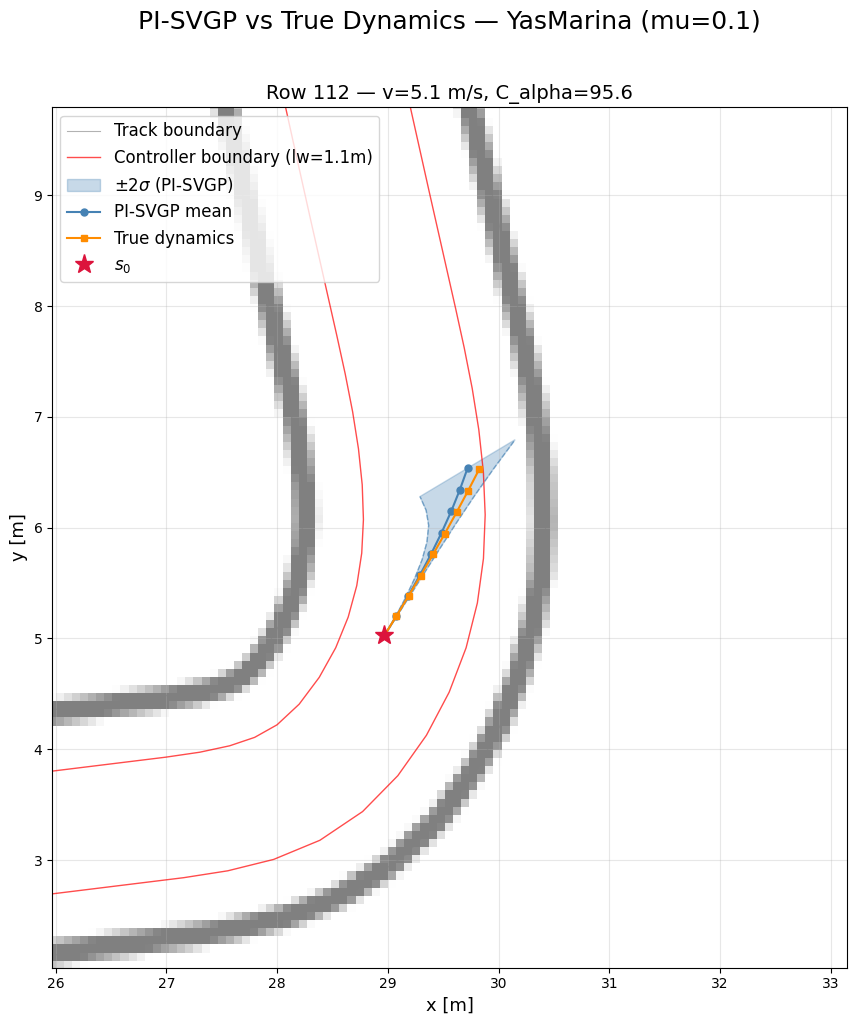

In [46]:
# ── Usage ────────────────────────────────────────────────────────────────────
csv_path = "../results/mcts_pi_svgp_cs_extract_YasMarina_10/traj_config_mcts_dpw_pi_svgp_cpp_cs_extract_s42_YasMarina_10_20260219_110439.csv"
track_name = "YasMarina"
row_indices = [112]

plot_svgp_samples(
    csv_path=csv_path,
    track_name=track_name,
    row_indices=row_indices,
    # mu=1.0,
    mu=0.1,
    lane_width=1.1,
    friction="10489",
    n_samples=5000,
)

Saved: plot_res/svgp_samples_YasMarina_mu0.3_90_130.png


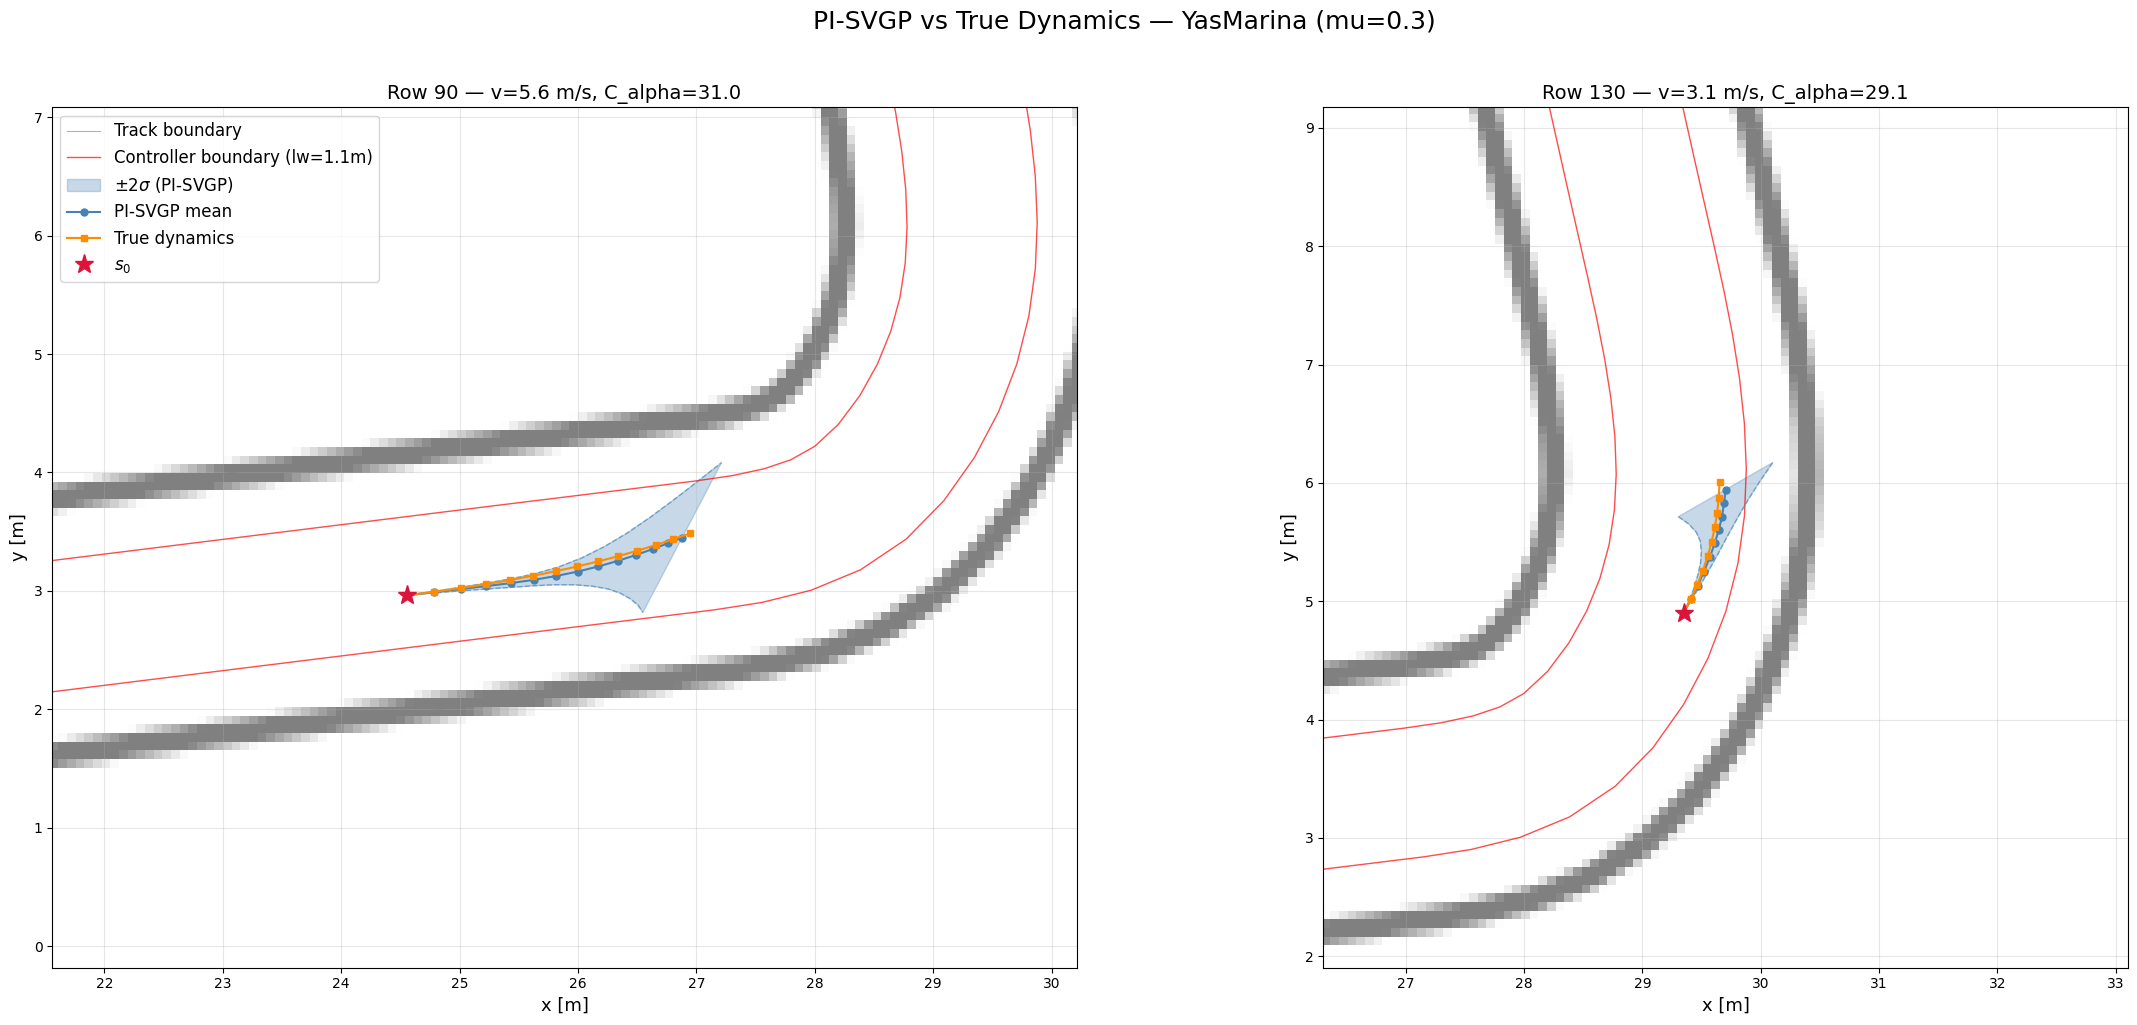

In [35]:
# ── Usage ────────────────────────────────────────────────────────────────────
csv_path = "../results/mcts_pi_svgp_cs_extract_YasMarina_03/traj_config_mcts_dpw_pi_svgp_cpp_cs_extract_s42_YasMarina_03_20260219_115617.csv"
track_name = "YasMarina"
row_indices = [90, 130]

plot_svgp_samples(
    csv_path=csv_path,
    track_name=track_name,
    row_indices=row_indices,
    mu=0.3,
    lane_width=1.1,
    friction="10489",
    n_samples=500,
)